In [153]:
from pathlib import Path
import os

# Keep relative input and output paths anchored at the project root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
if not (PROJECT_ROOT / "utils.py").is_file():
    raise RuntimeError(f"Open this notebook from the project root or experiments/: {Path.cwd()}")
os.chdir(PROJECT_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tmesh
from PIL import Image

from utils import segment_image


def draw_bbox_and_get_mask(image_input, bbox, label="Target Area", width=800, height=800):
    """
    Отрисовывает Bounding Box на картинке и создает 2D бинарную маску.

    :param image_input: путь к картинке (str) или PIL Image
    :param bbox: список координат [xmin, ymin, xmax, ymax] в пикселях
    :param label: надпись над рамкой
    :return: mask (numpy array bool 2D)
    """
    if isinstance(image_input, str):
        img = Image.open(image_input)
    else:
        img = image_input

    xmin, ymin, xmax, ymax = bbox
    w, h = xmax - xmin, ymax - ymin

    # 1. Отрисовка для проверки
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img)

    # Рисуем зеленую рамку
    rect = patches.Rectangle((xmin, ymin), w, h, linewidth=2, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)

    # Текст над рамкой
    if label:
        ax.text(xmin, max(0, ymin - 8), label, color='lime', fontsize=11, fontweight='bold')

    plt.title(f"BBox: {bbox}")
    plt.axis('off')
    plt.show()

    # 2. Создаем бинарную маску (True внутри рамки, False снаружи)
    mask = np.zeros((height, width), dtype=bool)
    mask[ymin:ymax, xmin:xmax] = True
    return mask

In [154]:
from utils import segment_image, visualize_segmentation

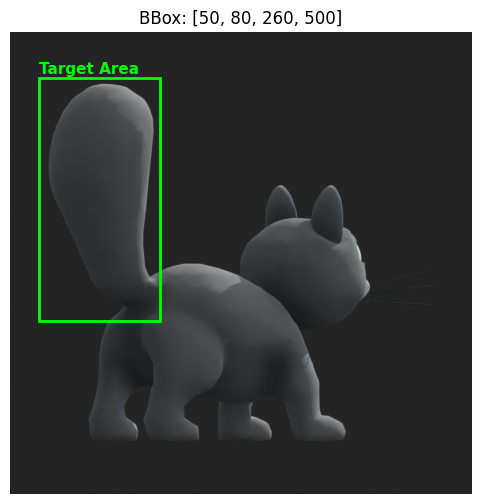

./weights are already installed


KeyboardInterrupt: 

In [155]:
draw_bbox_and_get_mask('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/back.png', [50,80,260,500])
back = segment_image('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/back.png', 50, 80, 260, 500)

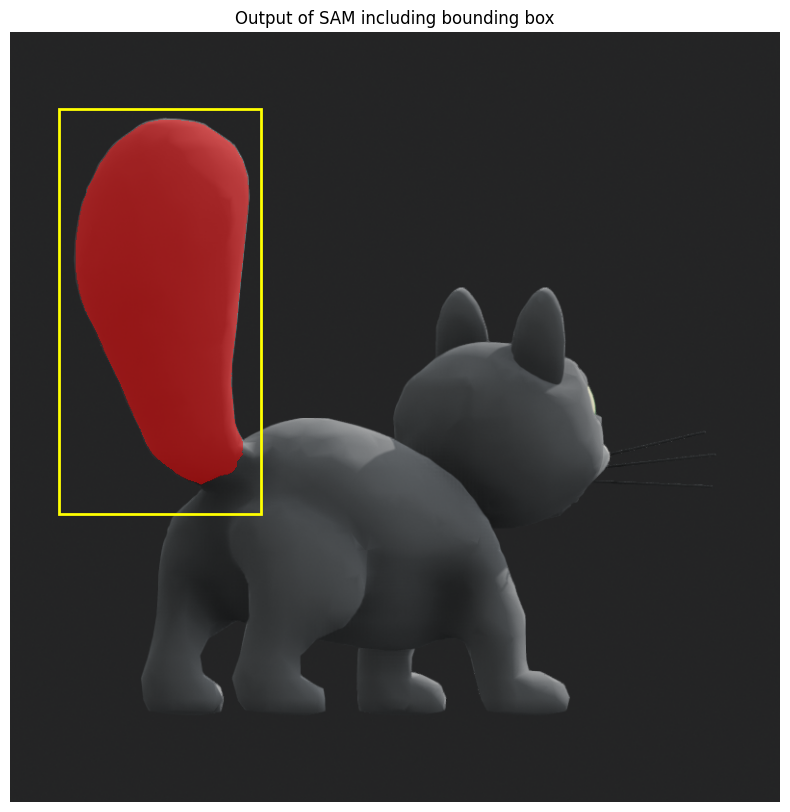

In [126]:
visualize_segmentation('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/back.png', back, 50, 80, 260, 500)

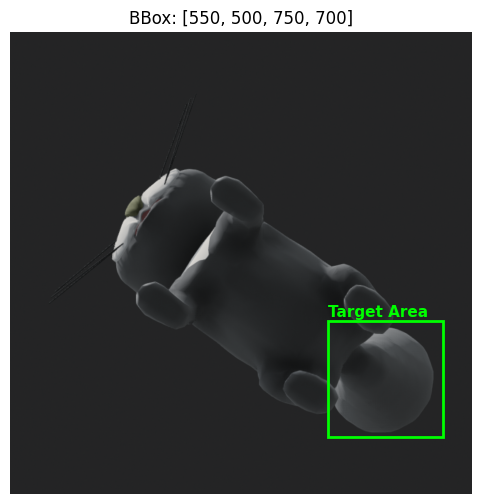

./weights are already installed


In [127]:
draw_bbox_and_get_mask('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/bottom.png', [550,500,750,700])
bottom = segment_image('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/bottom.png', 550, 500, 750, 700)

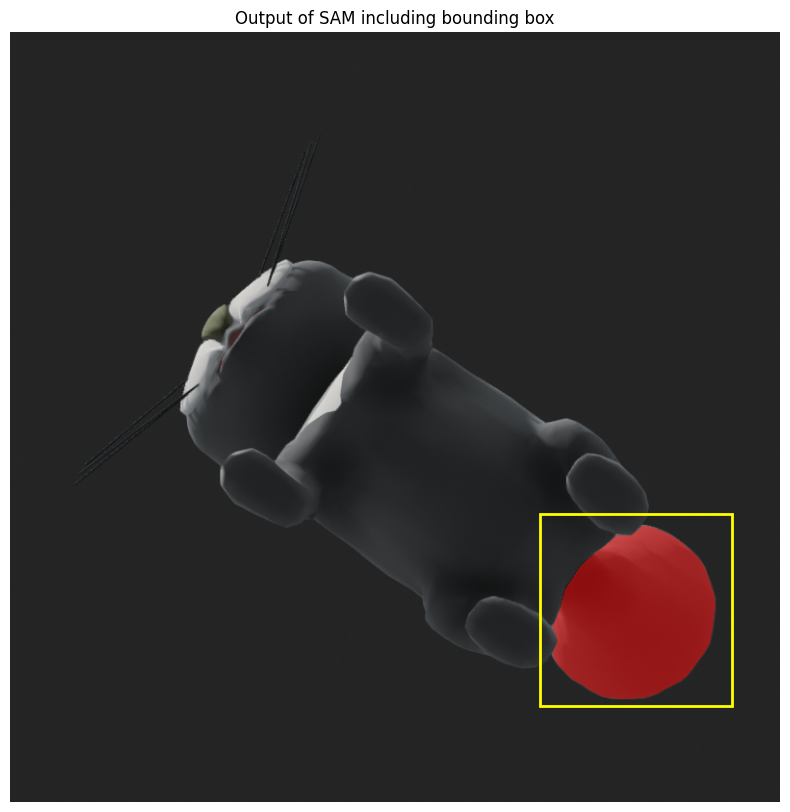

In [128]:
visualize_segmentation('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/bottom.png', bottom, 550, 500, 750, 700)

In [129]:
back = segment_image('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/back.png', 50, 80, 260, 500)

./weights are already installed


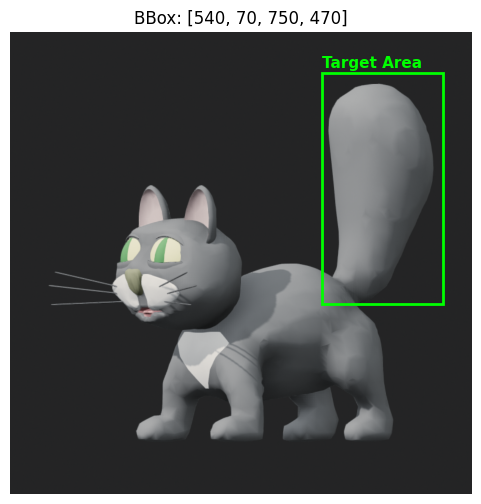

./weights are already installed


In [130]:
draw_bbox_and_get_mask('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/front.png', [540,70,750,470])
front = segment_image('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/front.png', 540, 70, 750, 470)

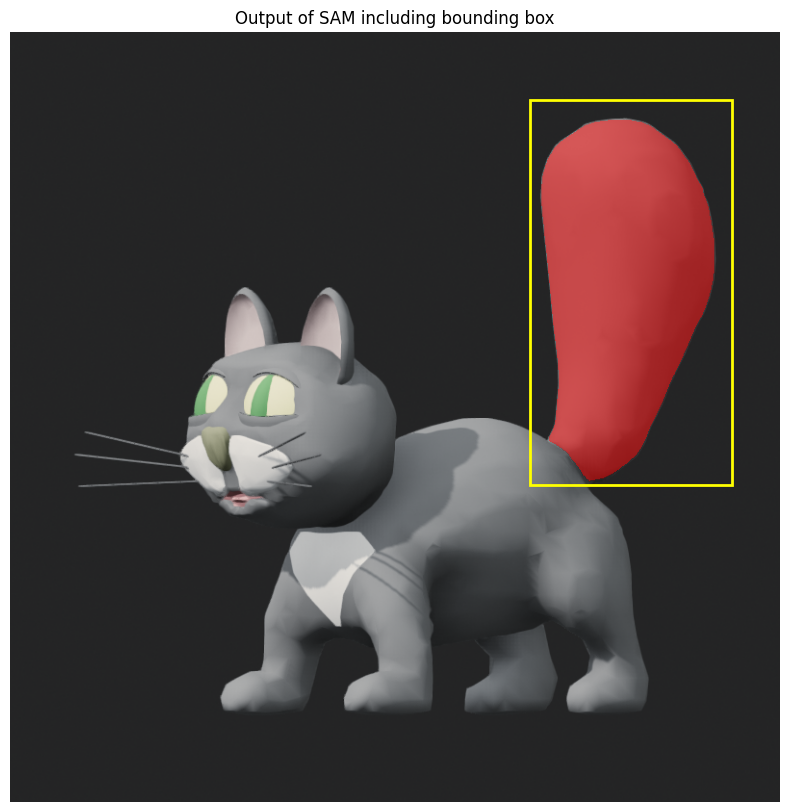

In [131]:
visualize_segmentation('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/front.png', front, 540, 70, 750, 470)

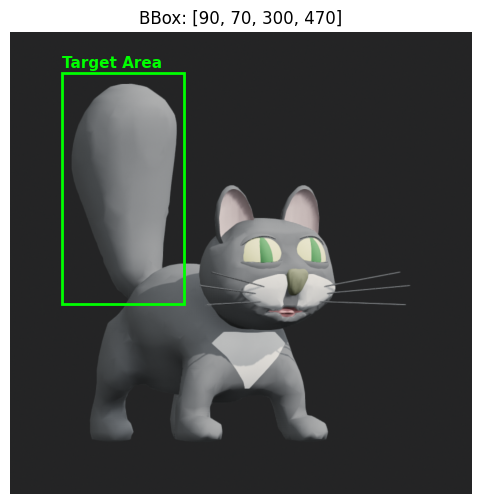

./weights are already installed


In [132]:
draw_bbox_and_get_mask('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/left.png', [90,70,300,470])
left = segment_image('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/left.png', 90, 70, 300, 470)

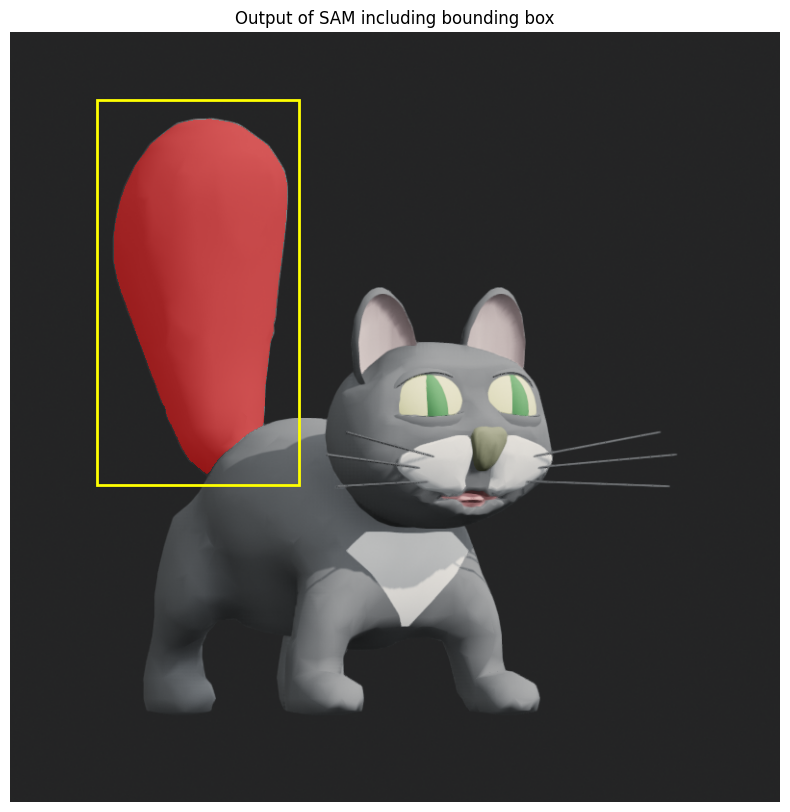

In [133]:
visualize_segmentation('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/left.png', left, 90, 70, 300, 470)

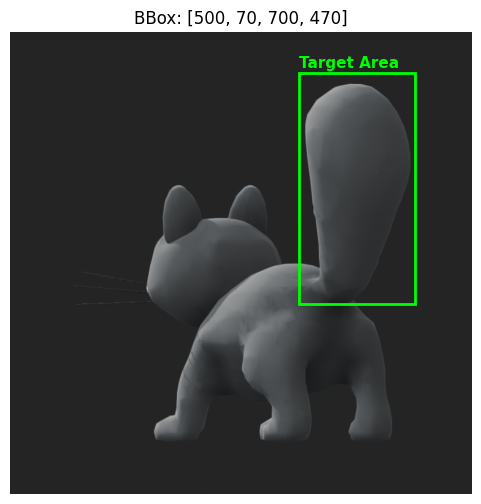

./weights are already installed


In [134]:
draw_bbox_and_get_mask('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/right.png', [500,70,700,470])
right = segment_image('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/right.png', 500, 70, 700, 470)

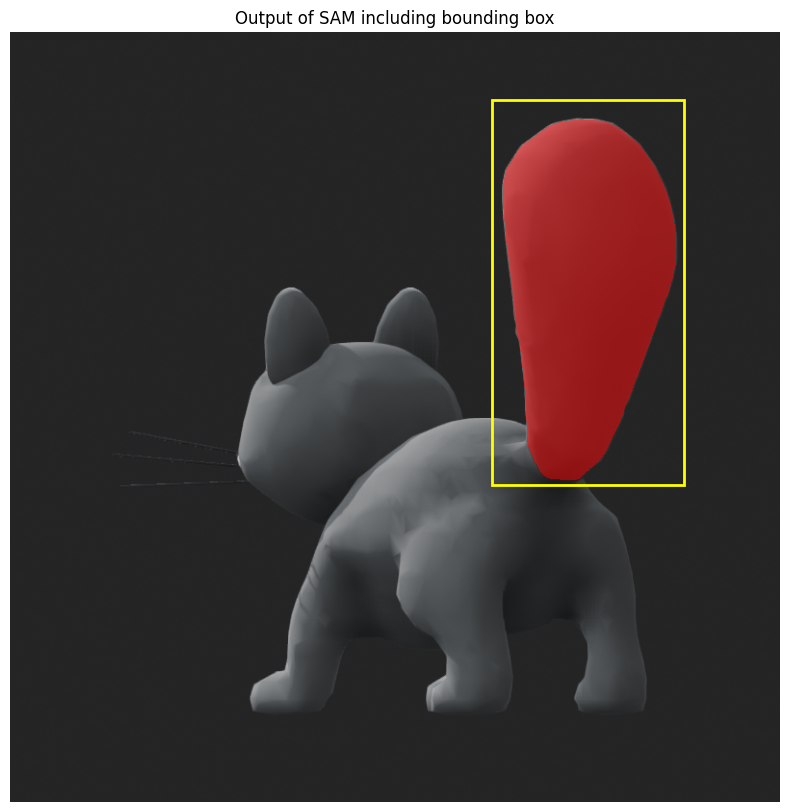

In [135]:
visualize_segmentation('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/right.png', right, 500, 70, 700, 470)

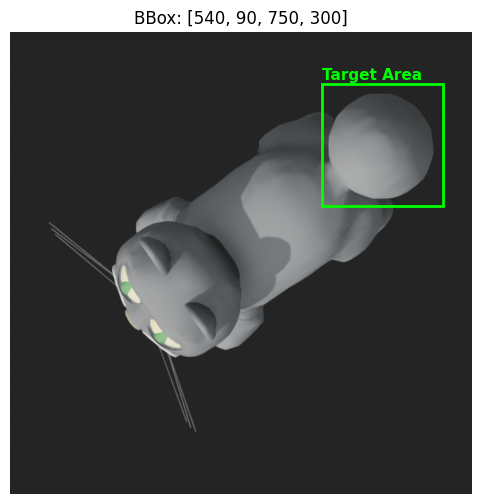

./weights are already installed


In [136]:
draw_bbox_and_get_mask('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/top.png', [540,90,750,300])
top = segment_image('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/top.png', 540, 90, 750, 300)

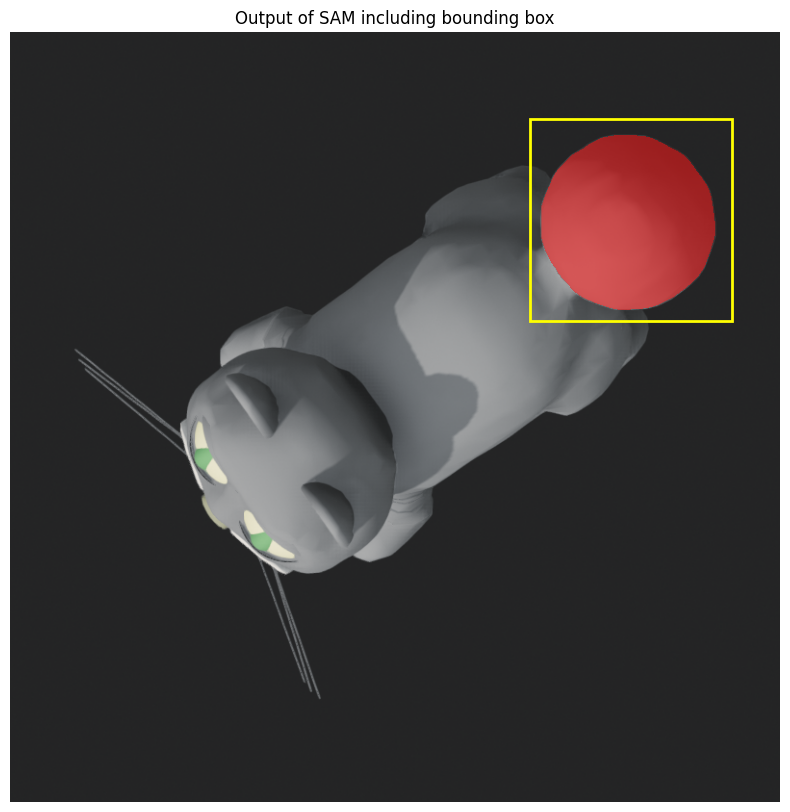

In [137]:
visualize_segmentation('rendered_views/1f32bc0b4dd740f49faefc1cbe0e5e45/top.png', top, 540, 90, 750, 300)

In [138]:
from ObjaverseDataset import ObjaverseDataset
from torch.utils.data import DataLoader

dataset = ObjaverseDataset(uids=["41b9b4576fd043b9bcda02fc9e9fd138", "1f32bc0b4dd740f49faefc1cbe0e5e45"],category="Lego", start_index=1, limit=10)
dataloader = DataLoader(dataset, batch_size=1, shuffle=False, collate_fn=dataset.collate_fn)

In [139]:
import os

In [140]:
import importlib
from utils import *

#importlib.reload(utils)

<module 'utils' from '/Users/marinazaspa/PycharmProjects/vlm-based-3d-shape-editing/utils.py'>

In [ ]:
# 1. Рендерим ракурсы и получаем список туплей [(eye_pos, file_path), ...]
rendered_data = render_6_views(tmesh, output_dir="rendered_views")

# 2. Формируем структуру с масками (замените load_mask_for на вашу логику получения маски)
masks_input = []
for eye, file_path in rendered_data:
    mask = load_mask_for(file_path)  # Получение маски (numpy array или PIL Image)
    masks_input.append((mask, eye))

# 3. Запускаем проекцию 3D
colored_mesh, mask_submesh = project_masks_to_3d(tmesh, masks_input, width=1008, height=1008)

In [141]:
from utils import _remove_platform_only, project_masks_to_3d
import glob

# 1. Загружаем или получаем исходную 3D модель (без платформы)
tmesh = _remove_platform_only(dataset[1]["mesh"])

# 2. Загружаем ваши 6 масок (предполагается, что картинки сохранены или созданы)
masks_dict = {"front": front, "back":back, "left":left, "right":right, "top":top, "bottom":bottom}


# 3. Запускаем обратный рейкастинг
colored_mesh, mask_submesh = project_masks_to_3d(tmesh, masks_dict, width=800, height=800)

# 4. Получение списка вершин и граней 3D-маски:
mask_vertices = mask_submesh.vertices  # NumPy массив (N, 3)
mask_faces = mask_submesh.faces        # NumPy массив (M, 3)

print(f"Вершин в 3D маске: {len(mask_vertices)}")
print(f"Граней в 3D маске: {len(mask_faces)}")



Вершин в 3D маске: 654
Граней в 3D маске: 1238


In [145]:
import trimesh

# Принудительно конвертируем визуал модели в ColorVisuals
colored_mesh.visual = trimesh.visual.ColorVisuals(
    mesh=colored_mesh,
    vertex_colors=colored_mesh.visual.vertex_colors
)

# Теперь отобразятся цвета!
colored_mesh.show()

AttributeError: 'TextureVisuals' object has no attribute 'vertex_colors'

In [148]:
# Проверяем, нужно ли конвертировать
if not isinstance(colored_mesh.visual, trimesh.visual.ColorVisuals):
    colored_mesh.visual = colored_mesh.visual.to_color()

colored_mesh.show()

In [149]:
# 1. Показываем только саму выделенную 3D-маску (submesh)
print("Отображение выделенной 3D-маски:")
mask_submesh.show()

# 2. Показываем всю исходную модель с наложенной цветом маской
print("Отображение полной модели с наложенной маской:")
if hasattr(colored_mesh, 'visual') and not isinstance(colored_mesh.visual, trimesh.visual.ColorVisuals):
    colored_mesh.visual = colored_mesh.visual.to_color()

colored_mesh.show()

Отображение выделенной 3D-маски:
Отображение полной модели с наложенной маской:
